# 02 · Returns analysis (with a short sales section)
**Project:** Why are customers returning orders? Returns, discount & delivery analysis

Uses the clean tables from `01_data_cleaning.ipynb`. Every number here is also calculated in SQL (`sql/03`–`sql/08`),
so the notebook is mainly for the charts used in the README.

**Part 1: Returns (main story)**
1. How much comes back? (return rate and cost of returns)
2. Return rate by category
3. Return rate by region and country
4. Returns over time
5. Which products and customers drive returns
6. Delivery charges

**Part 2: Sales and customers (short)**
7. Monthly sales, categories, repeat customers

**Return rate** = returned value ÷ gross sales value. Returns include cancellations, because the data books both as credit notes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMG = ROOT / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)

# one simple chart style for every figure
BLUE, ORANGE, GREY = "#2A78D6", "#EB6834", "#898781"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e1",
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")

def pounds(x, _=None):
    return f"£{x/1000:,.0f}k"

In [2]:
lines = pd.read_csv(DATA / "order_lines.csv", dtype={"invoice_no": str, "stock_code": str, "customer_id": str},
                    parse_dates=["invoice_date"])
products = pd.read_csv(DATA / "products.csv", dtype={"stock_code": str})
countries = pd.read_csv(DATA / "countries.csv")
delivery = pd.read_csv(DATA / "delivery_charges.csv", dtype={"invoice_no": str, "customer_id": str})

# join the product category and region onto every line (same as the SQL JOINs)
df = (lines.merge(products[["stock_code", "description", "category"]], on="stock_code", how="left")
           .merge(countries[["country", "country_clean", "region", "shipping_zone"]], on="country", how="left"))

# two helper columns make every return calculation a simple sum
df["sales_value"] = df["line_value"].where(df["line_type"] == "Sale", 0)
df["returned_value"] = -df["line_value"].where(df["line_type"] == "Return", 0)
df["month"] = df["invoice_date"].dt.to_period("M").dt.to_timestamp()
print(f"{len(df):,} lines from {df.invoice_date.min():%d %b %Y} to {df.invoice_date.max():%d %b %Y}")

1,021,120 lines from 01 Dec 2009 to 09 Dec 2011


In [3]:
def return_table(group_col):
    # gross sales, returned value and return rate for any grouping column
    t = df.groupby(group_col).agg(gross_sales=("sales_value", "sum"), returned_value=("returned_value", "sum"))
    t["return_rate"] = t["returned_value"] / t["gross_sales"]
    t["return_rate_pct"] = (t["return_rate"] * 100).round(2)   # easier to read in the table
    return t.sort_values("return_rate", ascending=False)

# Part 1 · Returns
## 1. How much comes back?

In [4]:
gross = df["sales_value"].sum()
returned = df["returned_value"].sum()
pd.Series({
    "Gross sales": f"£{gross:,.0f}",
    "Returned value (cost of returns)": f"£{returned:,.0f}",
    "Return rate": f"{returned / gross:.2%}",
    "Sales invoices": f"{df.loc[df.line_type == 'Sale', 'invoice_no'].nunique():,}",
    "Credit notes (returns)": f"{df.loc[df.line_type == 'Return', 'invoice_no'].nunique():,}",
}, name="value").to_frame()

,value
Gross sales,"£19,396,454"
Returned value (cost of returns),"£470,773"
Return rate,2.43%
Sales invoices,"39,514"
Credit notes (returns),"7,403"


## 2. Return rate by category

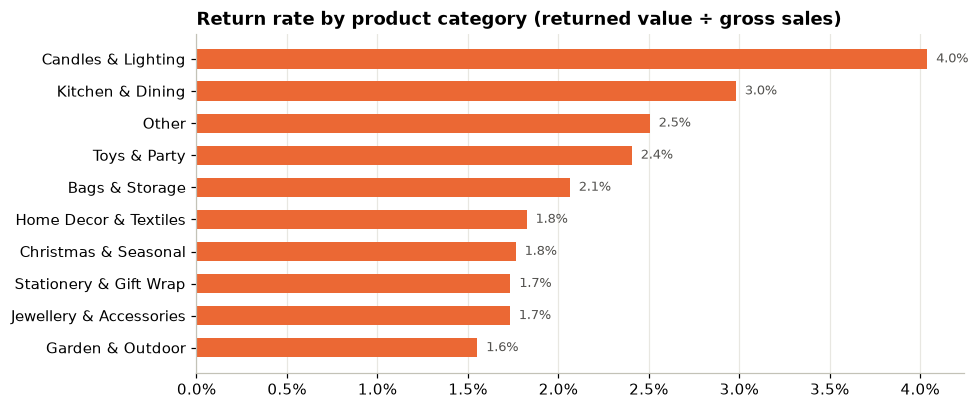

,gross_sales,returned_value,return_rate,return_rate_pct
category,,,,
Candles & Lighting,"1,663,929.34","67,216.20",0.04,4.04
Kitchen & Dining,"5,460,728.32","162,816.59",0.03,2.98
Other,"826,748.19","20,711.93",0.03,2.51
Toys & Party,"1,587,331.13","38,196.13",0.02,2.41
Bags & Storage,"2,651,399.95","54,716.21",0.02,2.06
Home Decor & Textiles,"3,627,694.34","66,202.49",0.02,1.82
Christmas & Seasonal,"943,568.75","16,650.71",0.02,1.76
Stationery & Gift Wrap,"1,240,031.23","21,515.15",0.02,1.74
Jewellery & Accessories,"607,830.51","10,529.49",0.02,1.73


In [5]:
by_cat = return_table("category")
fig, ax = plt.subplots(figsize=(9, 4))
c = by_cat.sort_values("return_rate")
ax.barh(c.index, c["return_rate"], color=ORANGE, height=0.6)
for i, v in enumerate(c["return_rate"]):
    ax.text(v + 0.0005, i, f"{v:.1%}", va="center", fontsize=8.5, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.grid(axis="y", visible=False)
ax.set_title("Return rate by product category (returned value ÷ gross sales)")
save(fig, "return_rate_by_category"); plt.show()
by_cat

## 3. Return rate by region and country

In [6]:
return_table("region")

,gross_sales,returned_value,return_rate,return_rate_pct
region,,,,
EU,"2,362,827.24","72,532.88",0.03,3.07
Rest of World,"287,536.04","8,337.52",0.03,2.90
United Kingdom,"16,597,641.58","388,612.16",0.02,2.34
Europe (non-EU),"137,521.48","1,268.21",0.01,0.92
Unspecified,"10,927.16",22.00,0.00,0.20


In [7]:
return_table("shipping_zone")

,gross_sales,returned_value,return_rate,return_rate_pct
shipping_zone,,,,
International,"2,787,884.76","82,138.61",0.03,2.95
Domestic,"16,597,641.58","388,612.16",0.02,2.34
Unknown,"10,927.16",22.00,0.00,0.20


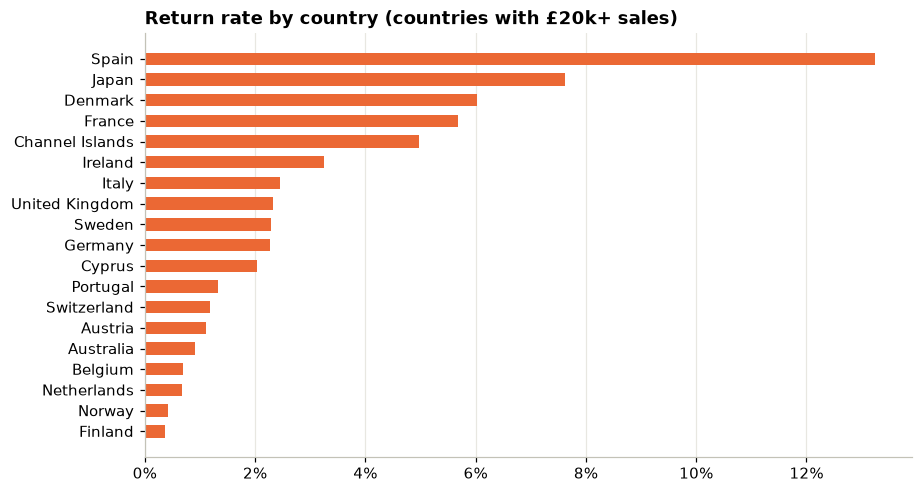

,gross_sales,returned_value,return_rate,return_rate_pct
country_clean,,,,
Spain,"97,766.75","12,955.19",0.13,13.25
Japan,"43,023.91","3,277.14",0.08,7.62
Denmark,"67,422.69","4,067.10",0.06,6.03
France,"311,090.29","17,659.09",0.06,5.68
Channel Islands,"44,030.33","2,188.52",0.05,4.97
Ireland,"623,414.16","20,297.55",0.03,3.26
Italy,"28,937.50",710.70,0.02,2.46
United Kingdom,"16,553,611.25","386,423.64",0.02,2.33
Sweden,"86,319.14","1,973.97",0.02,2.29


In [8]:
# countries with at least £20k of sales, so tiny markets don't top the list by chance
by_country = return_table("country_clean")
by_country = by_country[by_country["gross_sales"] >= 20000]
fig, ax = plt.subplots(figsize=(9, 5))
c = by_country.sort_values("return_rate")
ax.barh(c.index, c["return_rate"], color=ORANGE, height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Return rate by country (countries with £20k+ sales)")
save(fig, "return_rate_by_country"); plt.show()
by_country

In [9]:
# Spain tops the list. How much of Spain's returned value comes from its single biggest returner?
spain = df[df["country_clean"] == "Spain"].groupby("customer_id")["returned_value"].sum().sort_values(ascending=False)
print(f"Top Spanish customer: {spain.iloc[0] / spain.sum():.0%} of Spain's returned value")

Top Spanish customer: 95% of Spain's returned value


## 4. Returns over time

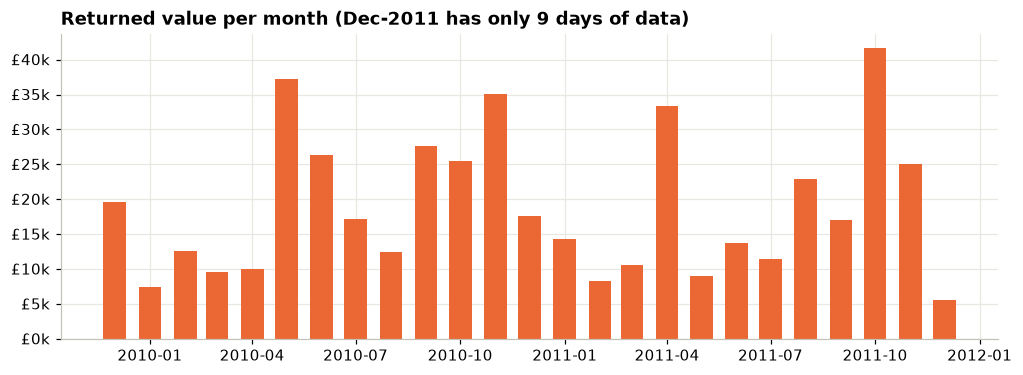

,gross_sales,returned_value,return_rate
month,,,
2009-12-01,"797,708.32","19,558.08",0.02
2010-01-01,"612,271.20","7,465.63",0.01
2010-02-01,"537,893.54","12,575.44",0.02
2010-03-01,"761,665.62","9,603.85",0.01
2010-04-01,"646,233.18","10,025.26",0.02
2010-05-01,"643,474.28","37,192.89",0.06
2010-06-01,"696,439.47","26,336.86",0.04
2010-07-01,"632,983.51","17,132.73",0.03
2010-08-01,"674,036.87","12,397.60",0.02


In [10]:
monthly = df.groupby("month").agg(gross_sales=("sales_value", "sum"), returned_value=("returned_value", "sum"))
monthly["return_rate"] = monthly["returned_value"] / monthly["gross_sales"]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(monthly.index, monthly["returned_value"], width=20, color=ORANGE)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(pounds))
ax.set_title("Returned value per month (Dec-2011 has only 9 days of data)")
save(fig, "returns_by_month"); plt.show()
monthly

## 5. Which products and customers drive returns?

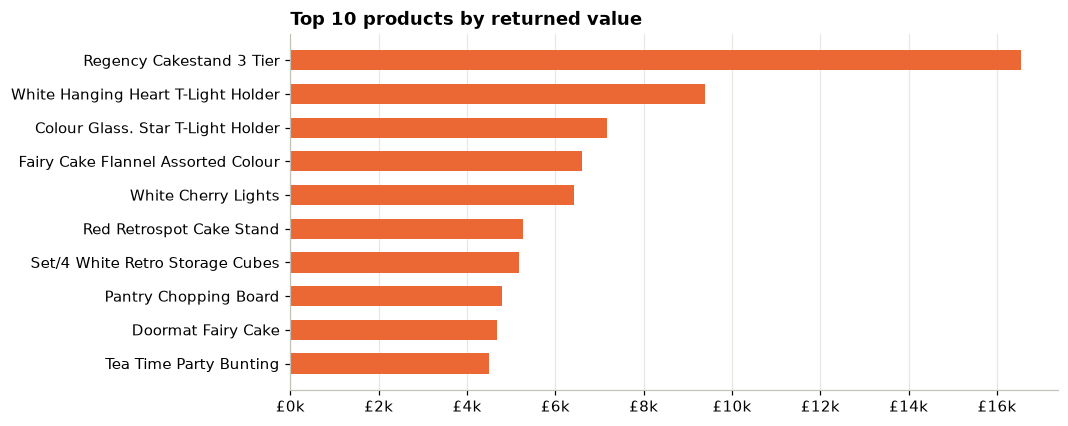

,description,category,gross_sales,returned_value,return_rate
3298,REGENCY CAKESTAND 3 TIER,Kitchen & Dining,"330,590.32","16,545.30",0.05
4468,WHITE HANGING HEART T-LIGHT HOLDER,Candles & Lighting,"261,168.73","9,387.10",0.04
978,COLOUR GLASS. STAR T-LIGHT HOLDER,Candles & Lighting,"44,680.75","7,164.12",0.16
1381,FAIRY CAKE FLANNEL ASSORTED COLOUR,Kitchen & Dining,"25,407.27","6,614.37",0.26
4447,WHITE CHERRY LIGHTS,Candles & Lighting,"18,048.72","6,421.10",0.36
3242,RED RETROSPOT CAKE STAND,Kitchen & Dining,"64,918.30","5,270.25",0.08
3798,SET/4 WHITE RETRO STORAGE CUBES,Bags & Storage,"43,844.96","5,187.65",0.12
2723,PANTRY CHOPPING BOARD,Kitchen & Dining,"5,868.50","4,803.06",0.82
1188,DOORMAT FAIRY CAKE,Kitchen & Dining,"45,723.84","4,678.68",0.10
4146,TEA TIME PARTY BUNTING,Kitchen & Dining,"27,564.75","4,490.50",0.16


In [11]:
by_product = (df.groupby(["description", "category"])
                .agg(gross_sales=("sales_value", "sum"), returned_value=("returned_value", "sum"))
                .reset_index())
by_product["return_rate"] = by_product["returned_value"] / by_product["gross_sales"]
top10 = by_product.sort_values("returned_value", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 4.2))
t = top10.sort_values("returned_value")
ax.barh(t["description"].str.title(), t["returned_value"], color=ORANGE, height=0.6)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(pounds))
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 products by returned value")
save(fig, "top_returned_products"); plt.show()
top10

In [12]:
share_top10 = top10["returned_value"].sum() / by_product["returned_value"].sum()
print(f"The top 10 products are {share_top10:.0%} of all returned value "
      f"(out of {(by_product.returned_value > 0).sum():,} products with a return)")

The top 10 products are 15% of all returned value (out of 2,871 products with a return)


In [13]:
# customers (known ids only): how many ever return, and how concentrated are returns?
cust = (df[df["customer_id"] != "Unknown"].groupby("customer_id")
          .agg(gross_sales=("sales_value", "sum"), returned_value=("returned_value", "sum")))
cust = cust[cust["gross_sales"] > 0]
cust["return_rate"] = cust["returned_value"] / cust["gross_sales"]
cust["return_band"] = pd.cut(cust["return_rate"], bins=[-0.001, 0, 0.02, 0.05, 0.10, 100],
                             labels=["No returns", "Under 2%", "2-5%", "5-10%", "10% or more"])
bands = cust.groupby("return_band", observed=False).agg(customers=("gross_sales", "size"),
                                                        gross_sales=("gross_sales", "sum"),
                                                        returned_value=("returned_value", "sum"))
bands["share_of_returns"] = bands["returned_value"] / bands["returned_value"].sum()
bands

,customers,gross_sales,returned_value,share_of_returns
return_band,,,,
No returns,3433,"3,432,096.03",0.00,0.00
Under 2%,1195,"7,779,698.91","68,408.27",0.15
2-5%,643,"3,545,541.97","114,290.22",0.25
5-10%,284,"1,187,889.42","77,170.61",0.17
10% or more,297,"877,102.99","203,025.00",0.44


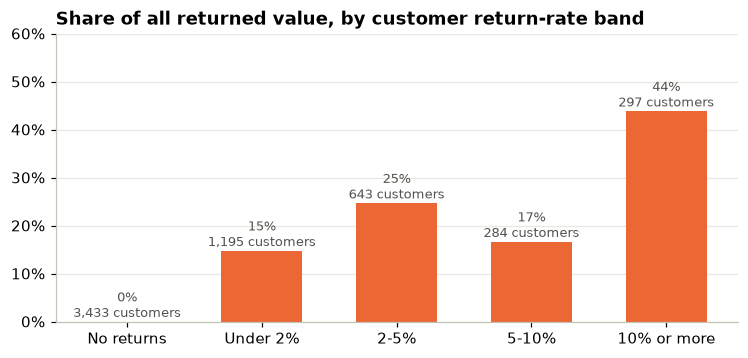

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(bands.index.astype(str), bands["share_of_returns"], color=ORANGE, width=0.6)
for i, (v, n) in enumerate(zip(bands["share_of_returns"], bands["customers"])):
    ax.text(i, v + 0.01, f"{v:.0%}\n{n:,} customers", ha="center", fontsize=8.5, color="#52514e")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.6); ax.grid(axis="x", visible=False)
ax.set_title("Share of all returned value, by customer return-rate band")
save(fig, "returns_by_customer_band"); plt.show()

## 6. Delivery charges
The data has no delivery dates. Postage and carriage lines are the only delivery information, so this section shows
how often a delivery charge appears on an order and how big it is, for UK vs international customers.

In [15]:
orders = (df[df["line_type"] == "Sale"].groupby(["invoice_no", "shipping_zone"])["line_value"].sum()
            .rename("goods_value").reset_index())
postage = delivery[delivery["line_type"] == "Sale"].groupby("invoice_no")["line_value"].sum().rename("postage")
orders = orders.join(postage, on="invoice_no")
orders["has_postage"] = orders["postage"].notna()

delivery_summary = orders.groupby("shipping_zone").agg(orders=("invoice_no", "size"),
                                                      pct_with_postage=("has_postage", "mean"),
                                                      postage_charged=("postage", "sum"),
                                                      goods_value=("goods_value", "sum"))
delivery_summary["postage_pct_of_goods"] = delivery_summary["postage_charged"] / delivery_summary["goods_value"]
delivery_summary

,orders,pct_with_postage,postage_charged,goods_value,postage_pct_of_goods
shipping_zone,,,,,
Domestic,36236,0.04,"313,499.48","16,597,641.58",0.02
International,3254,0.58,"112,907.80","2,787,884.76",0.04
Unknown,24,0.00,0.00,"10,927.16",0.00


# Part 2 · Sales and customers (short)

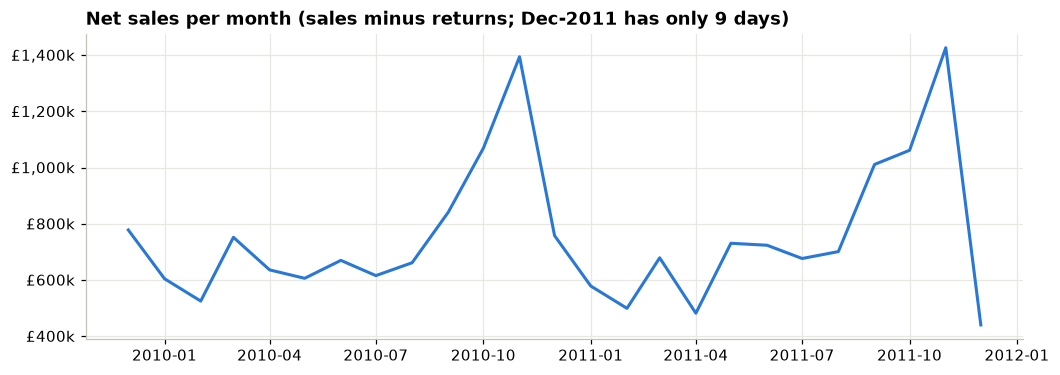

In [16]:
monthly_sales = df.groupby("month")["line_value"].sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(monthly_sales.index, monthly_sales.values, color=BLUE, lw=2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(pounds))
ax.set_title("Net sales per month (sales minus returns; Dec-2011 has only 9 days)")
save(fig, "net_sales_by_month"); plt.show()

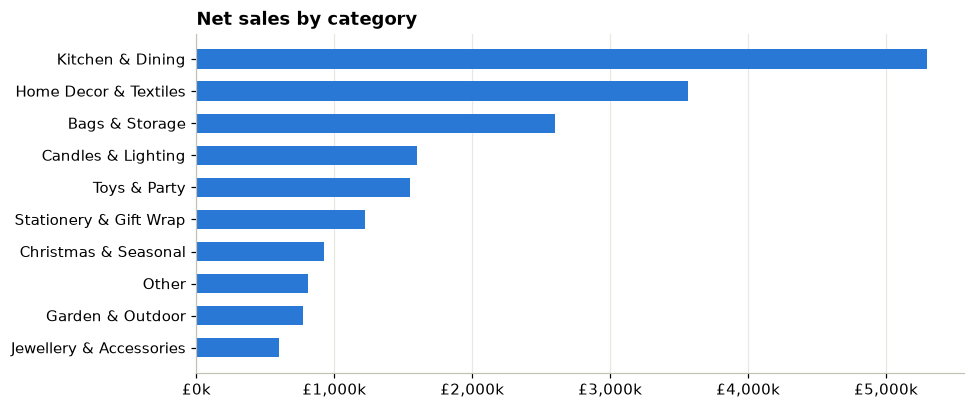

category
Kitchen & Dining           28.0%
Home Decor & Textiles      18.8%
Bags & Storage             13.7%
Candles & Lighting          8.4%
Toys & Party                8.2%
Stationery & Gift Wrap      6.4%
Christmas & Seasonal        4.9%
Other                       4.3%
Garden & Outdoor            4.1%
Jewellery & Accessories     3.2%
Name: line_value, dtype: str

In [17]:
by_cat_sales = df.groupby("category")["line_value"].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(by_cat_sales.index, by_cat_sales.values, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(pounds))
ax.grid(axis="y", visible=False)
ax.set_title("Net sales by category")
save(fig, "net_sales_by_category"); plt.show()
(by_cat_sales / by_cat_sales.sum()).sort_values(ascending=False).map("{:.1%}".format)

In [18]:
orders_per_customer = df[(df.customer_id != "Unknown") & (df.line_type == "Sale")].groupby("customer_id")["invoice_no"].nunique()
sales_per_customer = df[(df.customer_id != "Unknown") & (df.line_type == "Sale")].groupby("customer_id")["line_value"].sum()
repeat = orders_per_customer >= 2
print(f"Repeat customers: {repeat.mean():.1%} of known customers, "
      f"{sales_per_customer[repeat].sum() / sales_per_customer.sum():.1%} of their sales")

Repeat customers: 72.3% of known customers, 96.7% of their sales


# What the data shows
These are real numbers, but they come from one retailer in 2009–2011, so read them as practice findings, not general truths.

**Returns (main story)**
1. **About 2.4% of sales value comes back** as credit notes: £0.47m out of £19.4m gross sales. It is low because most
   customers are trade buyers ordering for their shops.
2. **Candles & Lighting has the highest return rate (4.0%)**, followed by Kitchen & Dining (3.0%). Both are full of fragile
   items (glass T-light holders, light chains, ceramic cake stands), which may explain part of it, but the data doesn't
   record return reasons, so that is a hypothesis to check, not a finding. Garden & Outdoor (1.6%) and Jewellery, Stationery and Christmas items (~1.7–1.8%) come back least.
3. **International orders come back more (2.9%) than UK orders (2.3%)**, and EU customers have the highest regional rate (3.1%).
4. **Country rankings are driven by single customers.** Spain's 13% return rate looks alarming, but one customer accounts for
   almost all of Spain's returned value. Before acting on a country, check how many customers are behind the number.
5. **Returns are concentrated.** The top 10 products are 15% of all returned value, and the 297 customers who return
   10%+ of what they buy account for about 44% of all returned value, while 58% of customers never return anything.
   That is a short list to investigate, not a company-wide problem.

**Delivery (limited data)**
6. Most UK orders have no delivery charge on the invoice (4%), while most international orders do (58%). Postage is about
   4% of goods value abroad vs 2% in the UK.

**Not possible with this data:** payment method / cash-on-delivery, discounts (only 177 discount lines, removed in cleaning),
and delivery times (there are no dispatch or delivery dates).

**Sales (short)**
7. Sales are highly seasonal: they climb from August and peak in November (Christmas stock for shops).
8. Kitchen & Dining and Home Decor are the biggest categories by sales.